# 16 — E0 Pilot: F1.a vs F2.a Across ρ Strata (Step 9)

The decision experiment: does the gap between frame-space composition (F1.a mean
frame) and score-space composition (F2.a equal-weight + z-score) grow as ρ drops?

Matrix: 3 pairs (from `resources/15_e0_selected_pairs.json`) × 2 methods × 20 prompts
× 2 batch orders (robustness replicate). Settings k=4, steps=32 (step-7 lesson:
presence-success needs longer generations than the golden settings).

Outputs (new files):
- `resources/16_e0_pilot.jsonl` — full evaluation log (harness)
- `resources/16_e0_summary.csv` — per-cell aggregates
- `resources/16_e0_gap_vs_rho.png` — THE plot

Medium pair bonus: `queen.n.02` presence is logged as a composition-success signal.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 32

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["selected"]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

COMPOSITION_TARGET = {"medium": "queen.n.02"}

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-08 19:34:36.021 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-08 19:34:36.024 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat("What is the most important thing in the world?", "The most important thing is"),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]
len(PROMPTS)

20

In [4]:
LOG_PATH = Path("resources/16_e0_pilot.jsonl")
LOG_PATH.unlink(missing_ok=True)  # new artifact of this notebook, not a baseline

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)

baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:02<00:00,  2.78s/it]

100%|██████████| 1/1 [00:02<00:00,  2.78s/it]

baseline ready


## The pilot matrix

For each stratum: build both concepts once (disk-cached), then run
F1.a (mean frame → vanilla single-concept loop) and F2.a (z-scored equal-weight
multi-guide), each in forward and reversed prompt order.

In [5]:
all_records = []

for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    mean_frame = Concept.average([concept_a, concept_b])
    synsets = [info["a"], info["b"]]
    if stratum in COMPOSITION_TARGET:
        synsets.append(COMPOSITION_TARGET[stratum])

    for order in ("forward", "reversed"):
        prompts = PROMPTS if order == "forward" else PROMPTS[::-1]
        baselines = baseline_texts if order == "forward" else baseline_texts[::-1]

        texts_f1, probe_f1 = fur.generate_with_topk_guide(
            prompts, guide=mean_frame, k=K, steps=STEPS
        )
        all_records += harness.evaluate(
            prompts, texts_f1, synsets,
            config={"stratum": stratum, "rho": info["rho"], "method": "F1.a", "order": order, "k": K, "steps": STEPS},
            probe=probe_f1, baseline_texts=baselines,
        )

        texts_f2, probe_f2 = fur.generate_with_topk_multi_guide(
            prompts, guides=[concept_a, concept_b], k=K, steps=STEPS, normalize="zscore"
        )
        all_records += harness.evaluate(
            prompts, texts_f2, synsets,
            config={"stratum": stratum, "rho": info["rho"], "method": "F2.a", "order": order, "k": K, "steps": STEPS},
            probe=probe_f2, baseline_texts=baselines,
        )
        print(f"{stratum} / {order}: done")

print(f"total records: {len(all_records)}")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:23<00:00, 23.13s/it]

100%|██████████| 1/1 [00:23<00:00, 23.13s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:23<00:00, 23.42s/it]

...

100%|██████████| 1/1 [00:24<00:00, 24.49s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:24<00:00, 24.49s/it]

100%|██████████| 1/1 [00:24<00:00, 24.49s/it]

high / reversed: done
total records: 240


In [6]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * 2 * 2 * len(PROMPTS), "one record per cell per prompt"
print(f"gate: {len(parsed)} records parse")

gate: 240 records parse


## Aggregate per cell

In [7]:
rows = []
for record in parsed:
    config = record["config"]
    pair_synsets = [SELECTION[config["stratum"]]["a"], SELECTION[config["stratum"]]["b"]]
    target = COMPOSITION_TARGET.get(config["stratum"])
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "order": config["order"],
            "success_a": record["success"][pair_synsets[0]],
            "success_b": record["success"][pair_synsets[1]],
            "success_both": record["success"][pair_synsets[0]] and record["success"][pair_synsets[1]],
            "success_target": record["success"].get(target) if target else None,
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

summary = (
    results.groupby(["stratum", "rho", "method"])
    .agg(
        a_rate=("success_a", "mean"),
        b_rate=("success_b", "mean"),
        both_rate=("success_both", "mean"),
        target_rate=("success_target", "mean"),
        mean_ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "method"])
)
summary.to_csv("resources/16_e0_summary.csv", index=False)
summary.round(3)

,stratum,rho,method,a_rate,b_rate,both_rate,target_rate,mean_ppl_ratio,flag_share
2,low,0.187,F1.a,0.0,0.05,0.0,NaN,8.546,0.90
3,low,0.187,F2.a,0.0,0.00,0.0,NaN,13.188,0.90
4,medium,0.321,F1.a,0.0,0.10,0.0,0.0,6.840,0.90
5,medium,0.321,F2.a,0.0,0.00,0.0,0.0,7.815,0.90
0,high,0.566,F1.a,0.0,0.00,0.0,NaN,8.909,0.85
1,high,0.566,F2.a,0.0,0.00,0.0,NaN,8.444,0.90


## Batch-order robustness

In [8]:
order_check = (
    results.groupby(["stratum", "method", "order"])["success_both"].mean().unstack()
)
order_check["delta"] = (order_check["forward"] - order_check["reversed"]).abs()
print(order_check.round(3))
print(f"\nmax |forward - reversed| both-rate delta: {order_check['delta'].max():.3f}")

order           forward  reversed  delta
stratum method                          
high    F1.a        0.0       0.0    0.0
        F2.a        0.0       0.0    0.0
low     F1.a        0.0       0.0    0.0
        F2.a        0.0       0.0    0.0
medium  F1.a        0.0       0.0    0.0
        F2.a        0.0       0.0    0.0

max |forward - reversed| both-rate delta: 0.000


## THE plot — F1-vs-F2 gap as a function of ρ

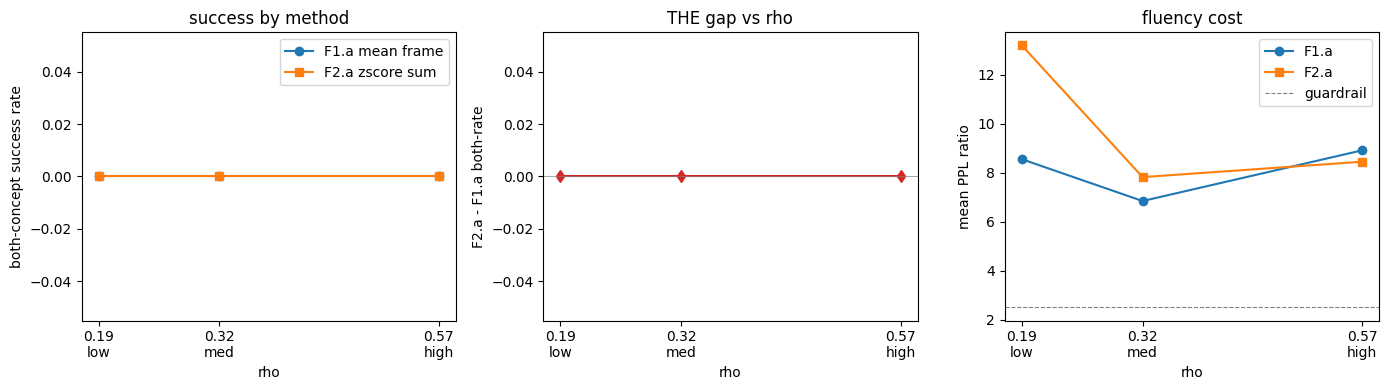

In [9]:
pivot = summary.groupby(["rho", "method"])[["a_rate", "b_rate", "both_rate", "mean_ppl_ratio"]].mean().reset_index()
f1 = pivot[pivot["method"] == "F1.a"].set_index("rho")
f2 = pivot[pivot["method"] == "F2.a"].set_index("rho")
rhos = sorted(f1.index)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(rhos, [f1.loc[r, "both_rate"] for r in rhos], "o-", label="F1.a mean frame")
axes[0].plot(rhos, [f2.loc[r, "both_rate"] for r in rhos], "s-", label="F2.a zscore sum")
axes[0].set_xlabel("rho")
axes[0].set_ylabel("both-concept success rate")
axes[0].set_title("success by method")
axes[0].legend()

gap = [f2.loc[r, "both_rate"] - f1.loc[r, "both_rate"] for r in rhos]
axes[1].plot(rhos, gap, "d-", color="tab:red")
axes[1].axhline(0, color="gray", lw=0.5)
axes[1].set_xlabel("rho")
axes[1].set_ylabel("F2.a - F1.a both-rate")
axes[1].set_title("THE gap vs rho")

axes[2].plot(rhos, [f1.loc[r, "mean_ppl_ratio"] for r in rhos], "o-", label="F1.a")
axes[2].plot(rhos, [f2.loc[r, "mean_ppl_ratio"] for r in rhos], "s-", label="F2.a")
axes[2].axhline(2.5, color="gray", ls="--", lw=0.8, label="guardrail")
axes[2].set_xlabel("rho")
axes[2].set_ylabel("mean PPL ratio")
axes[2].set_title("fluency cost")
axes[2].legend()

for ax in axes:
    ax.set_xticks(rhos)
    ax.set_xticklabels([f"{r:.2f}\n{s}" for r, s in zip(rhos, ["low", "med", "high"])])

plt.tight_layout()
plt.savefig("resources/16_e0_gap_vs_rho.png", dpi=150)
plt.show()

## Example generations per cell (eyeball check)

In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for method in ("F1.a", "F2.a"):
        example = next(
            r for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["method"] == method
            and r["config"]["order"] == "forward"
            and "short story" in r["prompt"]
        )
        print(f"[{stratum} / {method}] {answer(example['text'])[:140]}")
    print()

[low / F1.a] Once, a long-finger pianoforté was left behind by its traveling performer. In an antique music shop nestled in Paris's winding streets of Le
[low / F2.a] Once, in an old antique clockmaker's shop in Paris's charming Le Quartiers Latin quarter, an old, intricate pocket clock lay forgotten for m

[medium / F1.a] Once, a young artist lived a mundane office job. Every morning at exactly 7 am sharp, the artist, whose real-name wasn'Tina Thompson (though
[medium / F2.a] Once, in ancient Japan, a lone samuri named Hiro stumbled through mist-drenched mountains. He had spent his entire adult career serving as b

[high / F1.a] Once, on Moon Island (a small specks in an otherwise unremarkable archipelo in Japan) there was only 5 inhabitants.

There lived an eccentri
[high / F2.a] Once, on Moon Island (a small speck floating high up among stars), there existed an old watch. This was not just an old time-ticker; no,

